In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import seaborn as sns
import math
import random
import regex as re
import os
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from scipy import stats

In [2]:
x = np.linspace(0, 3, 100)
rng = np.random.RandomState(42)
y = np.sin(4 * x) + x + rng.uniform(size=len(x))
X = x[:, np.newaxis]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

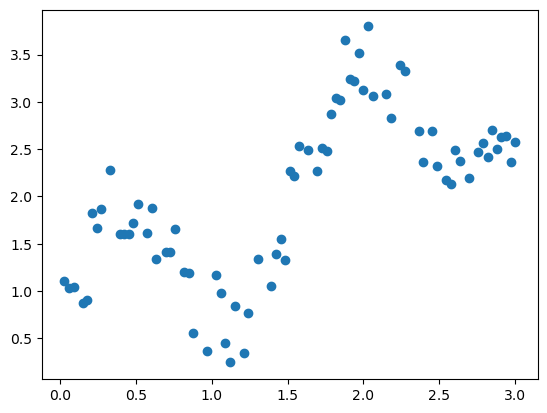

In [3]:
plt.scatter(X_train, y_train)
plt.show()

### So clearly, this is polynomial regression

Desipte that, try to implement linear regression on these datapoints and evaluate its performance

In [5]:
LinModel = LinearRegression()
LinModel.fit(X_train, y_train)

LinearRegression()

In [7]:
y_pred = LinModel.predict(X_test)

print("R2 factor:", LinModel.score(X_test, y_test))
print("MSE:", mean_squared_error(y_pred, y_test))

R2 factor: 0.41067297381418255
MSE: 0.7043403658672862


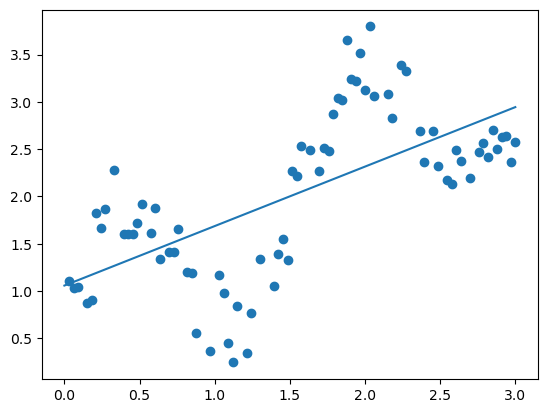

In [8]:
X_min = LinModel.coef_[0] * X.min() + LinModel.intercept_
X_max = LinModel.coef_[0] * X.max() + LinModel.intercept_

plt.scatter(X_train, y_train)
plt.plot([X.min(), X.max()], [X_min, X_max])

As you can conclude from the graph and the R2 factor, the model is not performing very well.

An R2 factor of 41% is under the acceptable threshold, which makes this model unusable. Though it's not the model's fault: it is forced to fit a straight line into a polynomial relationship. It therefore can't implement the pattern of the datapoints.

### Creating a polynomial regression model

Let's instead make a model that can actually fit the datapoints! Let's make a polynomial regression model!

In [12]:
PolyModel = LinearRegression()
PolyFactor = PolynomialFeatures(degree=0)

Tran_X_Train = PolyFactor.fit_transform(X_train)
Tran_X_Test = PolyFactor.fit_transform(X_test)

PolyModel.fit(Tran_X_Train, y_train)

LinearRegression()

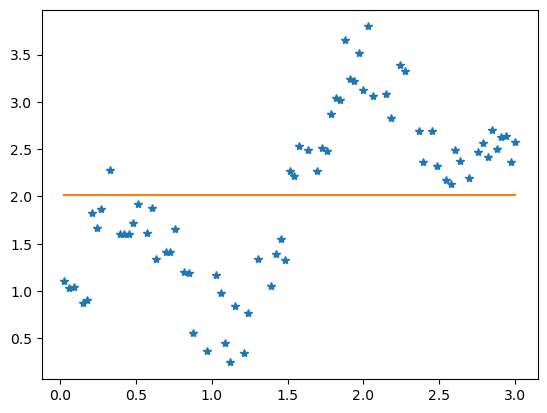

In [14]:
x = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
plt.plot(X_train, y_train, "*")
plt.plot(x, PolyModel.predict(PolyFactor.fit_transform(x)))
plt.show()

The R2 score of this model on the train set is: 0.8555374678146463


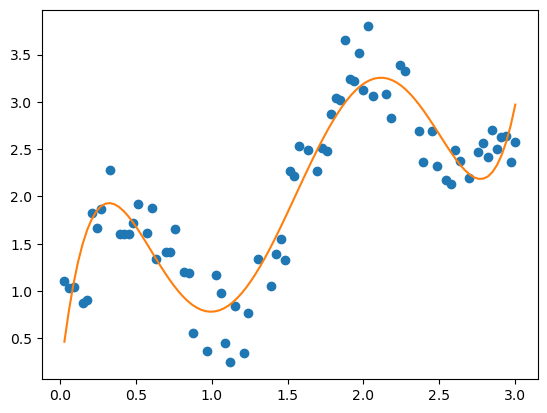

In [19]:
def poly_test(x):
    pol_exp = PolynomialFeatures(degree=x) # degree => Has a direct impact on the polynomial regression. It determines the amount of factors in the equation. Aka, the amount of times the line of best fit is allowed to bend.
    model = LinearRegression()
    model.fit(pol_exp.fit_transform(X_train), y_train)
    print('The R2 score of this model on the train set is:', model.score(pol_exp.fit_transform(X_train), y_train))
    x = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1,1) 
    plt.plot(X_train, y_train, 'o')
    plt.plot(x, model.predict(pol_exp.fit_transform(x))) 
    plt.show()
    
poly_test(5)    

# Exercise!

Now that we've brushed up on our polynomial regression knowledge, exercise with the auto.csv data.

In [21]:
df = pd.read_csv("Auto.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [22]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower        int64
weight            int64
acceleration    float64
model year        int64
origin            int64
car name         object
dtype: object

In [33]:
print(len(df["car name"].unique()))
print(len(df["car name"]))

305
398


In [34]:
df = df.drop("car name", axis=1)

In [ ]:
df = pd.get_dummies(df, columns=["origin"])

<Axes: >

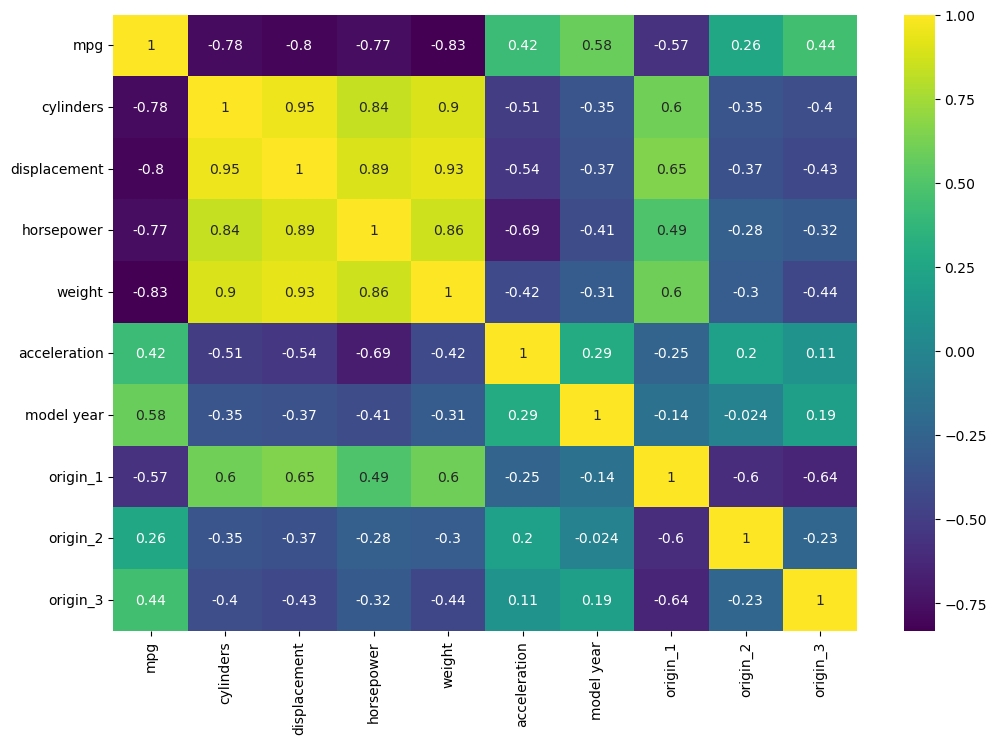

In [41]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), cmap="viridis",annot=True)

MPG => Cylinders, Displacement, Horsepower, Weight (Negative correlation)
MPG => model_year (positive correlation)

### Can you do it again? Do it agaaaiin, do it aaaggaaaiiinn, do it agaaiiinn

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Auto.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [3]:
df = df.drop("car name", axis=1)

In [7]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.402010,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.203079,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,76.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,95.000000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


<Axes: >

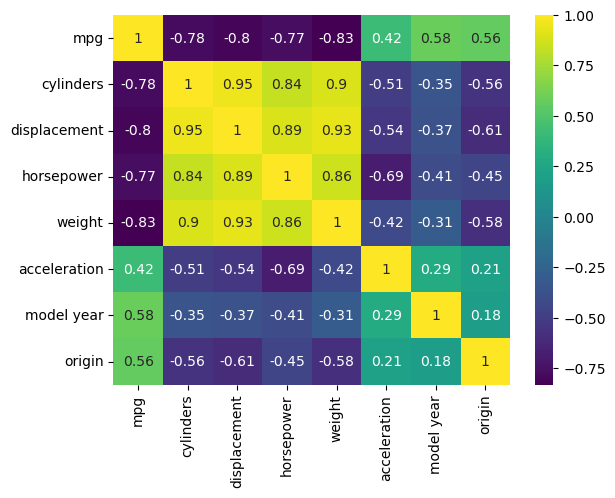

In [17]:
sns.heatmap(df.corr(), cmap="viridis", annot=True)

### Make a linear model from this data

In [18]:
X = df["weight"].to_numpy().reshape(-1, 1)
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

LinModel = LinearRegression()
LinModel.fit(X_train, y_train)

LinearRegression()

In [23]:
print(LinModel.score(X_train, y_train))
y_pred = LinModel.predict(X_test)

print(mean_squared_error(y_pred, y_test))

0.6803632329767397
15.460875948271058


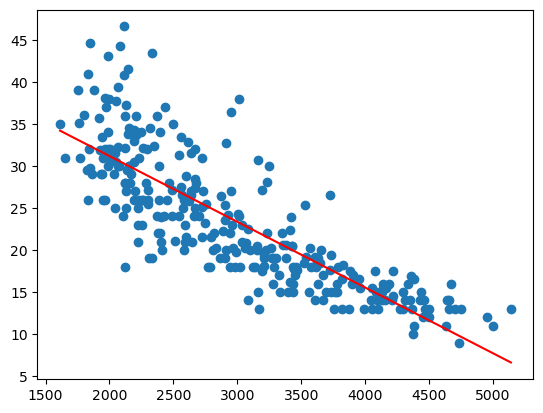

In [26]:
xmin = LinModel.coef_[0] * X.min() + LinModel.intercept_
xmax = LinModel.coef_[0] * X.max() + LinModel.intercept_

plt.scatter(X_train, y_train)
plt.plot([X.min(), X.max()], [xmin, xmax], color="red")

In [61]:
polymodel = LinearRegression()
polyfactor = PolynomialFeatures(degree=4)
X_Polytrain = polyfactor.fit_transform(X_train)

polymodel.fit(X_Polytrain, y_train)

LinearRegression()

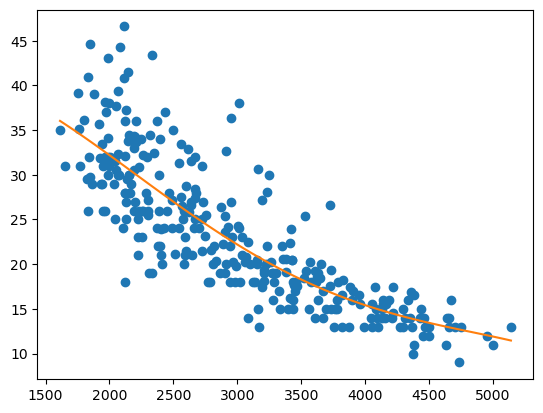

In [62]:
plt.plot(X_train, y_train, "o")
LineMagic = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
plt.plot(LineMagic, polymodel.predict(polyfactor.fit_transform(LineMagic)))

In [50]:
print(polymodel.score(X_Polytrain, y_train))
y_pred = polymodel.predict(polyfactor.fit_transform(X_test))
print(mean_squared_error(y_pred, y_test))

0.7000324439879628
13.53405878906435


In [59]:
train_mse = []
test_mse = []

for i in range(0, 50):
    print("degree:", i)

    PolyFact = PolynomialFeatures(degree=i)
    polymodel.fit(PolyFact.fit_transform(X_train), y_train)
    
    Train = PolyFact.fit_transform(X_train)
    Test = PolyFact.fit_transform(X_test)

    trainpred = polymodel.predict(Train)
    testpred = polymodel.predict(Test)

    train_mse.append(mean_squared_error(trainpred, y_train))
    test_mse.append(mean_squared_error(testpred, y_test))

for mse in test_mse:
    print(mse)


degree: 0
degree: 1
degree: 2
degree: 3
degree: 4
degree: 5
degree: 6
degree: 7
degree: 8
degree: 9
degree: 10
degree: 11
degree: 12
degree: 13
degree: 14
degree: 15
degree: 16
degree: 17
degree: 18
degree: 19
degree: 20
degree: 21
degree: 22
degree: 23
degree: 24
degree: 25
degree: 26
degree: 27
degree: 28
degree: 29
degree: 30
degree: 31
degree: 32
degree: 33
degree: 34
degree: 35
degree: 36
degree: 37
degree: 38
degree: 39
degree: 40
degree: 41
degree: 42
degree: 43
degree: 44
degree: 45
degree: 46
degree: 47
degree: 48
degree: 49
56.78590189631098
15.460875948271058
13.481137438463872
13.552298374406886
13.53405878906435
13.53157683990119
13.515105619179048
13.516502285525412
13.591062432660397
13.815702673305447
14.276545907485662
15.039131086982213
16.118667420884577
17.472790341612164
19.015815117971297
20.645053158785117
22.25491106351694
23.755758687542837
25.09165481160327
26.24193199342636
27.22290535942503
28.075644785785407
28.828334396188353
29.540099747680674
30.20796885

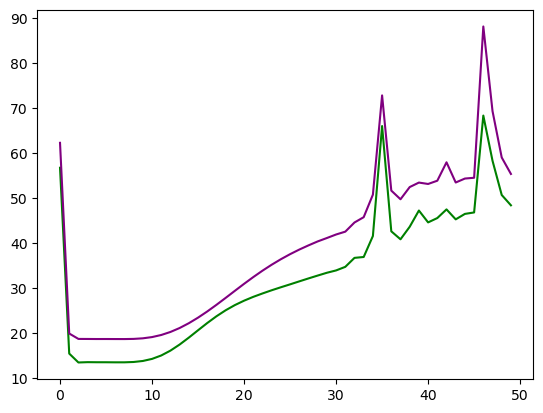

In [56]:
plt.plot(test_mse, color="green")
plt.plot(train_mse, color="purple")

In [57]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

train_mse = []
test_mse = []

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

polymodel = LinearRegression()  # or Ridge(alpha=1.0) for stability

for i in range(0, 50):
    print("degree:", i)

    PolyFact = PolynomialFeatures(degree=i)
    X_train_poly = PolyFact.fit_transform(X_train_scaled)
    X_test_poly  = PolyFact.transform(X_test_scaled)

    polymodel.fit(X_train_poly, y_train)

    trainpred = polymodel.predict(X_train_poly)
    testpred  = polymodel.predict(X_test_poly)

    train_mse.append(mean_squared_error(trainpred, y_train))
    test_mse.append(mean_squared_error(testpred, y_test))

degree: 0
degree: 1
degree: 2
degree: 3
degree: 4
degree: 5
degree: 6
degree: 7
degree: 8
degree: 9
degree: 10
degree: 11
degree: 12
degree: 13
degree: 14
degree: 15
degree: 16
degree: 17
degree: 18
degree: 19
degree: 20
degree: 21
degree: 22
degree: 23
degree: 24
degree: 25
degree: 26
degree: 27
degree: 28
degree: 29
degree: 30
degree: 31
degree: 32
degree: 33
degree: 34
degree: 35
degree: 36
degree: 37
degree: 38
degree: 39
degree: 40
degree: 41
degree: 42
degree: 43
degree: 44
degree: 45
degree: 46
degree: 47
degree: 48
degree: 49


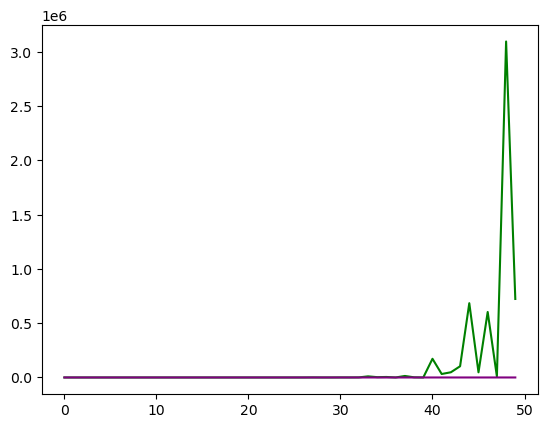

In [58]:
plt.plot(test_mse, color="green")
plt.plot(train_mse, color="purple")

In [63]:
polymodel.predict(polyfactor.fit_transform([[2071]]))

array([31.45763448])

In [69]:
X = df[["weight", "displacement", "model year"]]
y = df["mpg"]

mymodel = LinearRegression()
PolyJoy = PolynomialFeatures(degree=3)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=43)

mymodel.fit(PolyJoy.fit_transform(X_train), y_train)
y_pred = mymodel.predict(PolyJoy.fit_transform(X_test))

print("R2 factor:", mymodel.score(PolyJoy.fit_transform(X_train), y_train))
print("MSE score:", mean_squared_error(y_pred, y_test))

R2 factor: 0.8782746033746893
MSE score: 8.18211696052661


ValueError: X has 4 features, but LinearRegression is expecting 20 features as input.

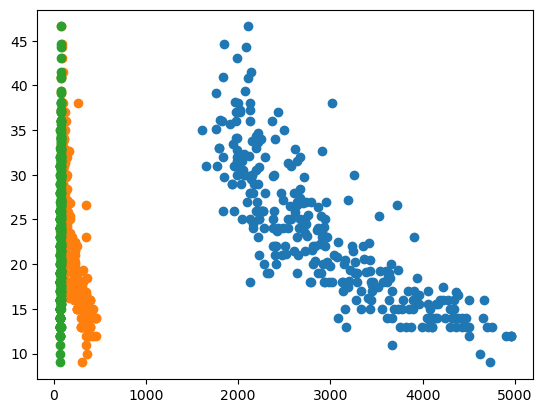

In [73]:
plt.plot(X_train, y_train, "o")
linemagic = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
plt.plot(linemagic, mymodel.predict(PolyJoy.fit_transform(linemagic)))